# France fiscal brief, 13 October 2026

French sovereign debt: the interest bill, the shortening stock, who bears the
rate risk, and what five 2027 political configurations do to it, set against
Redbox's own statistical benchmark.

This notebook is the executable form of the briefing note
`reports/briefing_FRA_AFT_2026-09/briefing_inline.html`. Run top to bottom, it

1. renders every chart from the flat files in `deliverables/` (plus the
   Eurostat debt history and balance sheet in `data/manual/`) with
   `ggfiscal.report.briefing_fra` (the descriptive charts and
   `key_figures.csv`), `ggfiscal.report.briefing_fra_scenarios` (the
   register rolled forward under each scenario by `ggfiscal.debt.simulate`)
   and `ggfiscal.report.briefing_fra_balance` (the asset side, net debt and
   the sell-down runs of `ggfiscal.debt.balance_sheet`) and
   `ggfiscal.report.briefing_fra_pensions` (the retirement-age exposure and
   impact matrix of `ggfiscal.debt.pension_age`);
2. fills the note's template with the values `tools/build_briefing_fra.py`
   computes and shows each section in the note's order;
3. writes `briefing.html` and `briefing_inline.html`, so the published page is
   reproduced by this notebook.

The questions for the AFT (section 9 of the note and the "To ask the AFT"
boxes) are left out here; the HTML keeps them. Facts marked **[ext]** come
from outside Redbox and are listed in section 9. Scenario assumptions are in
the tables of section 5; decisions D-S18-001 to D-S18-006, D-S19-001 (the
balance-sheet section, 7) and D-S20-001 (the retirement age, section 8) in `DECISIONS.md`.

In [1]:
import io

import pandas as pd
from IPython.display import HTML, SVG, Image as Image_display, display
from PIL import Image

from ggfiscal.debt import simulate as sim
from ggfiscal.report import briefing_fra, briefing_fra_balance, briefing_fra_pensions, briefing_fra_scenarios, france_brief

FIG = france_brief.BRIEF_DIR / "figures"
FIGS = briefing_fra_scenarios.render_all(FIG)     # scenarios_FRA.csv, decomposition, duration
FIGS.update(briefing_fra.render_all(FIG))         # descriptive charts, key_figures.csv
FIGS.update(briefing_fra_balance.render_all(FIG)) # balance_sheet_FRA.csv, ladder, selldown (D-S19-001)
FIGS.update(briefing_fra_pensions.render_all(FIG)) # pension_age_*.csv: the retirement-age matrix (D-S20-001)
france_brief.clear_cache()


def show(key, colours=96, width=1200):
    """Display a rendered PNG quantised to a small palette (D-S9-004: keep the
    notebook renderable on GitHub)."""
    im = Image.open(FIGS[key]).convert("RGB")
    if im.width > width:
        im = im.resize((width, round(im.height * width / im.width)), Image.LANCZOS)
    small = im.quantize(colours, dither=Image.Dither.NONE)
    buf = io.BytesIO(); small.save(buf, format="PNG", optimize=True)
    display(Image_display(data=buf.getvalue()))


def section(sid):
    """One section of the note: text and tables as HTML, charts as images."""
    for kind, value in france_brief.chunks(sid):
        if kind == "fig":
            show(value)
        elif kind == "svg":
            display(SVG(value))
        else:
            display(HTML(value))


missing = set(france_brief.figures()) - set(FIGS)
assert not missing, missing
print(f"{len(FIGS)} charts rendered into {FIG.relative_to(sim.ROOT)}; "
      f"{len(france_brief.figures())} appear in the brief")

32 charts rendered into reports/briefing_FRA_AFT_2026-09/figures; 31 appear in the brief


## Bottom line and key figures

In [2]:
section("s0")

Key figure,Value,Context
"Register stock, 10 Sep 2026","€2,937bn","uplifted; AFT total €2,904bn at 31 Aug"
"Avg coupon, fixed stock",2.14%,vs 10y OAT ≈ 4.85% at today's spread
GG interest 2025 → 2030 (status quo),2.2 → 4.0%,€65bn → €136bn
OAT redemptions 2027 / 28 / 29,203 / 246 / 281,"€bn; 2025 was €198bn, 2015–2024 €140–170bn"
"OAT–Bund 10y, 11 Oct 2026",135 bp,Bloomberg; September 2026 avg 101 bp; 2021 avg 38 bp
Value at risk per 100 bp,€140bn,"4.6% of GDP, on €2,344bn of OATs"


## 1. Where the stock stands

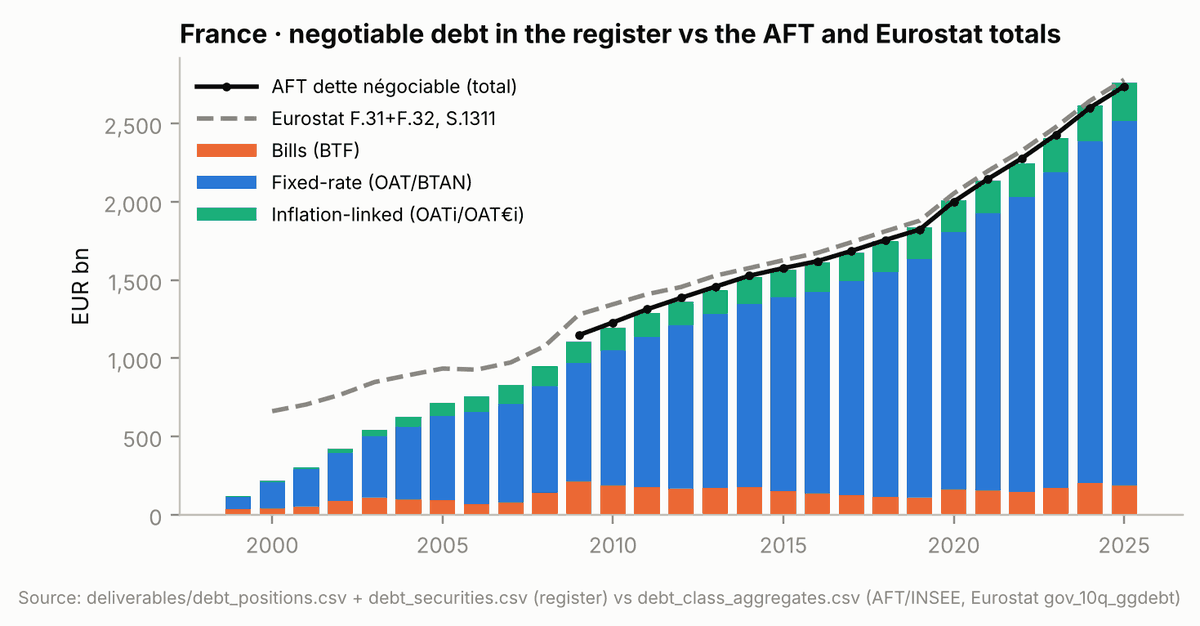

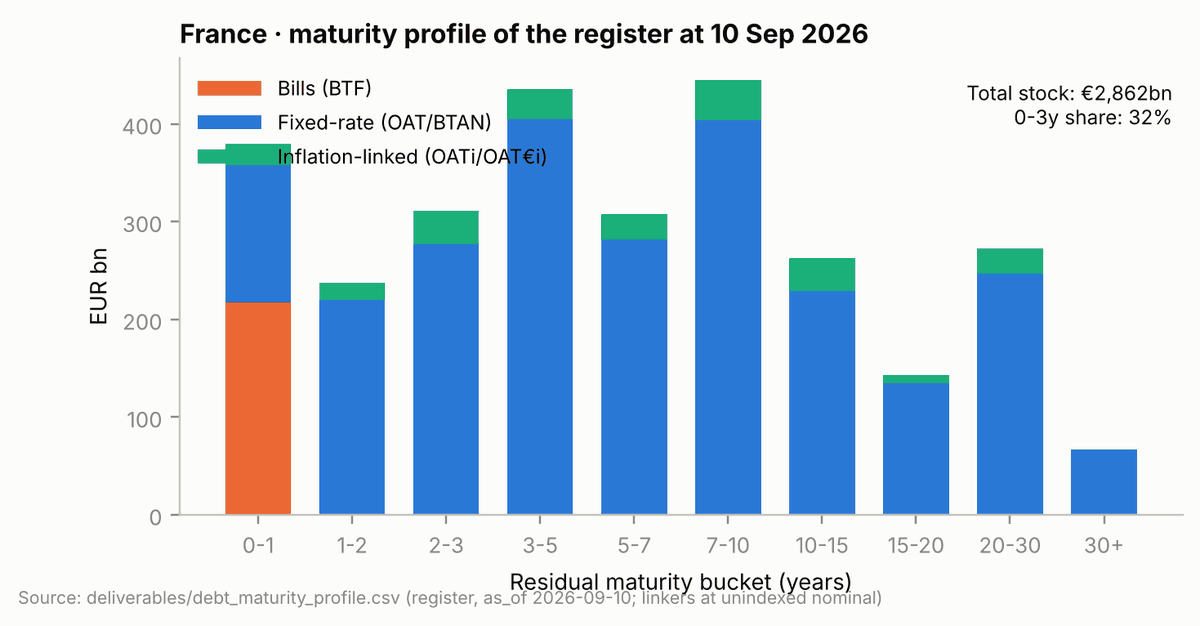

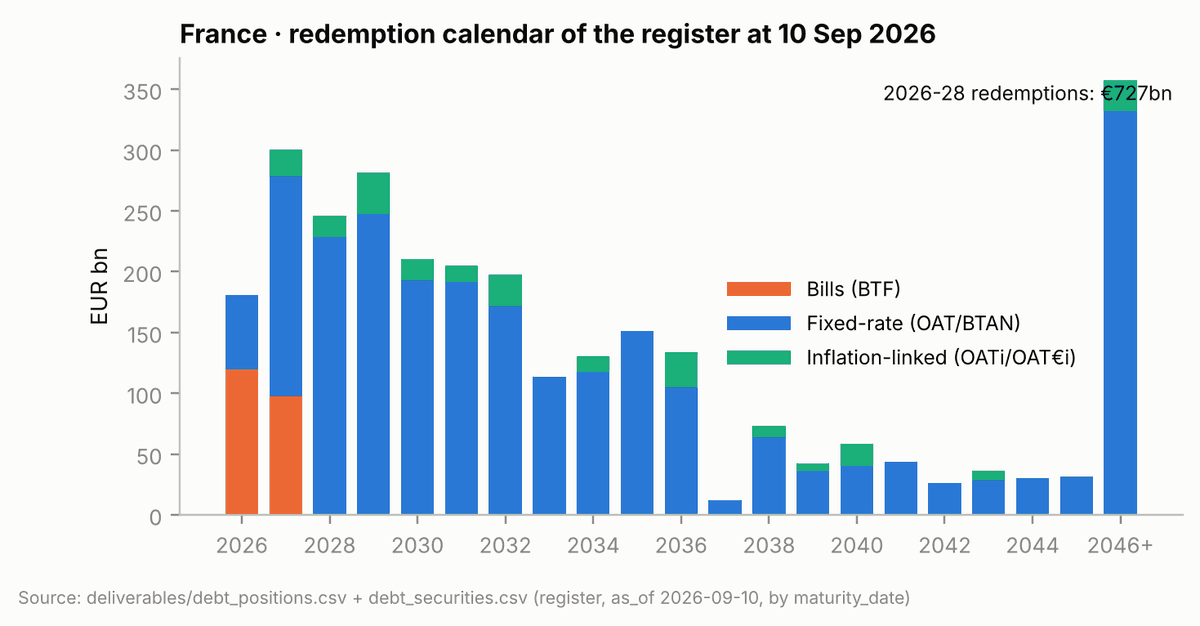

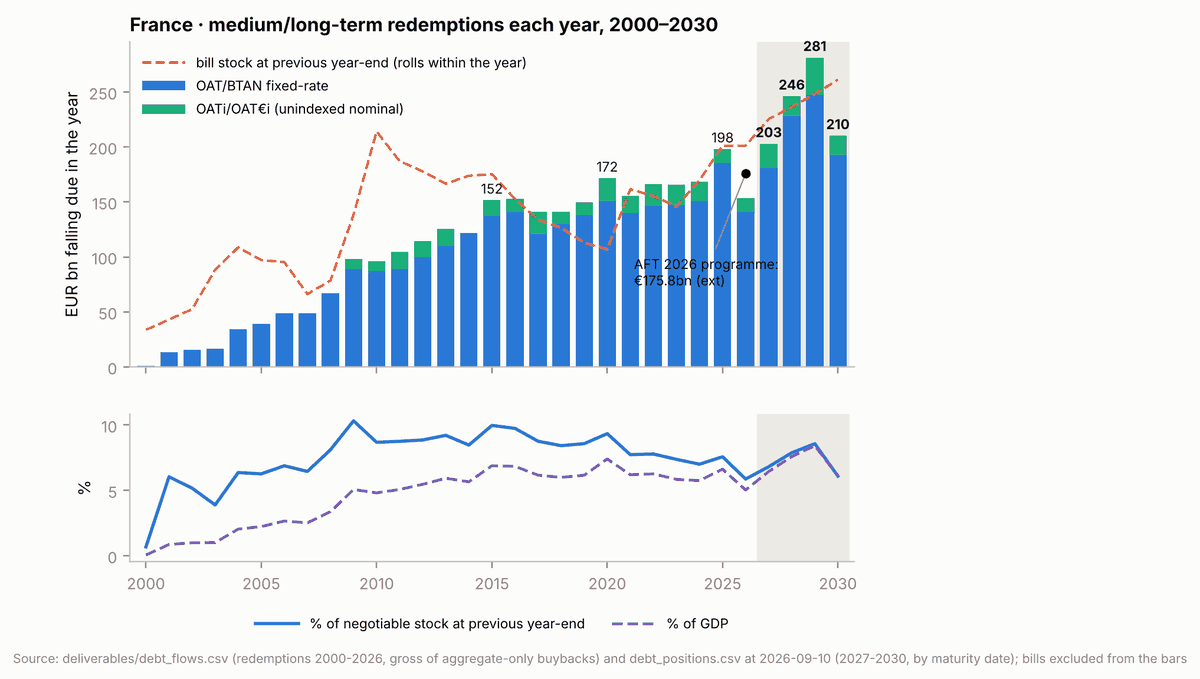

In [3]:
section("s1")

## 2. The interest bill and the wrong-way loop

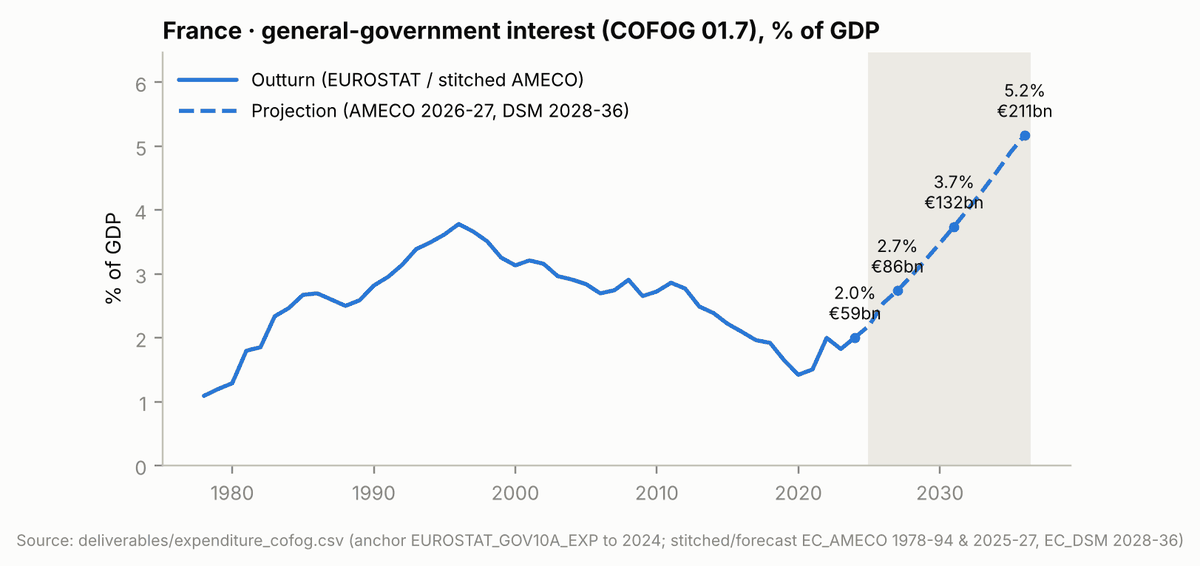

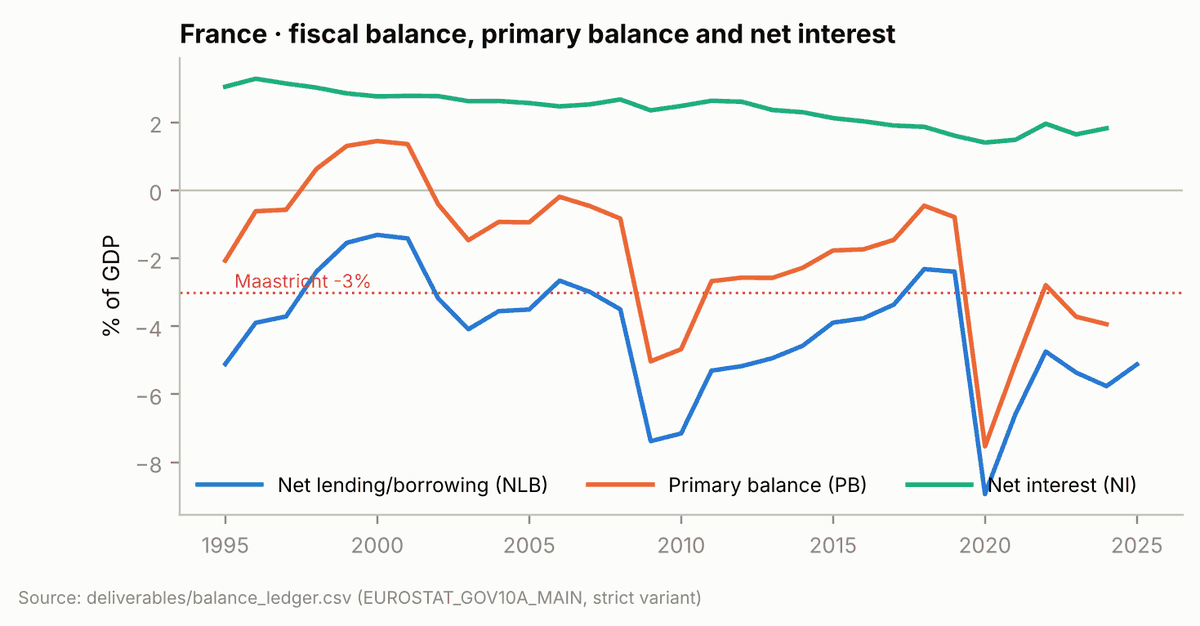

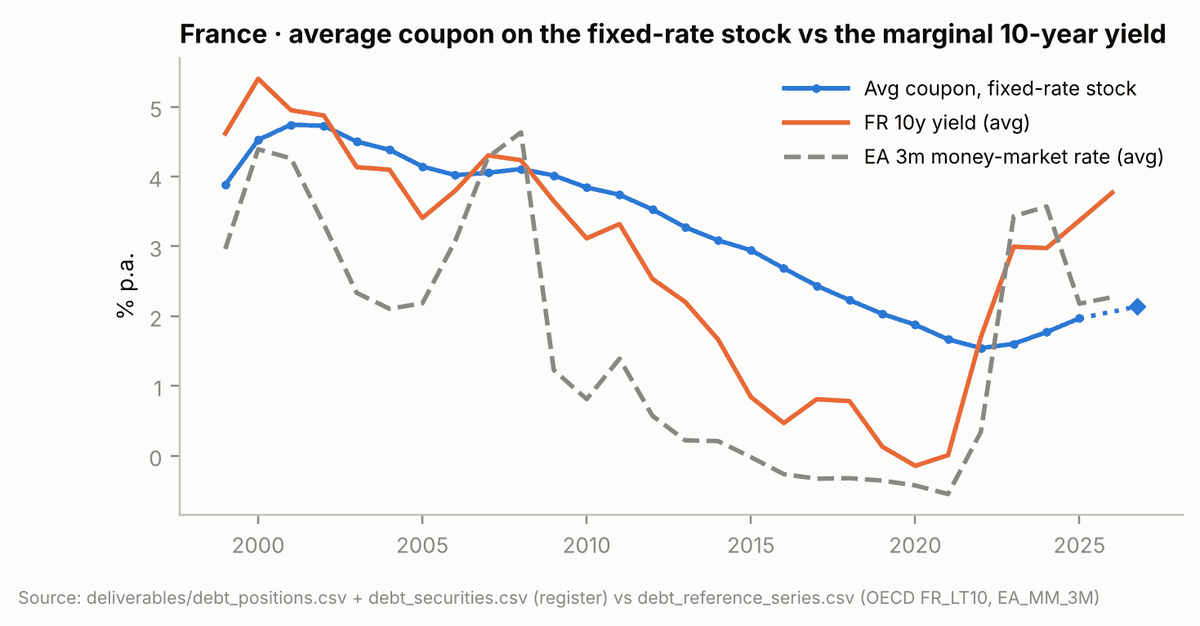

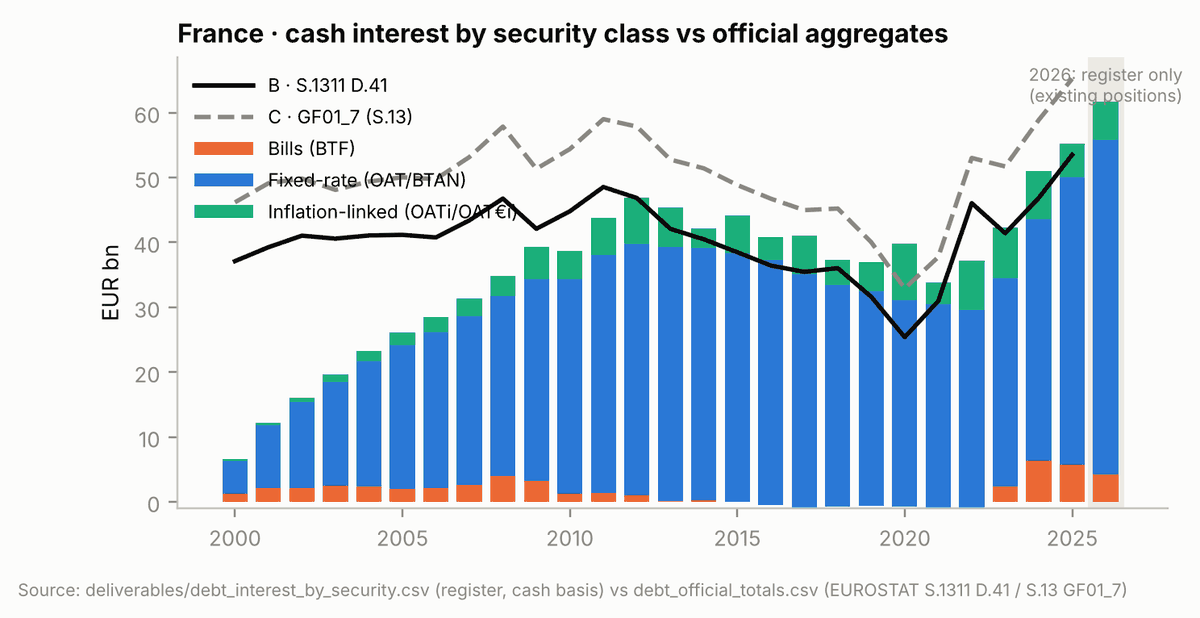

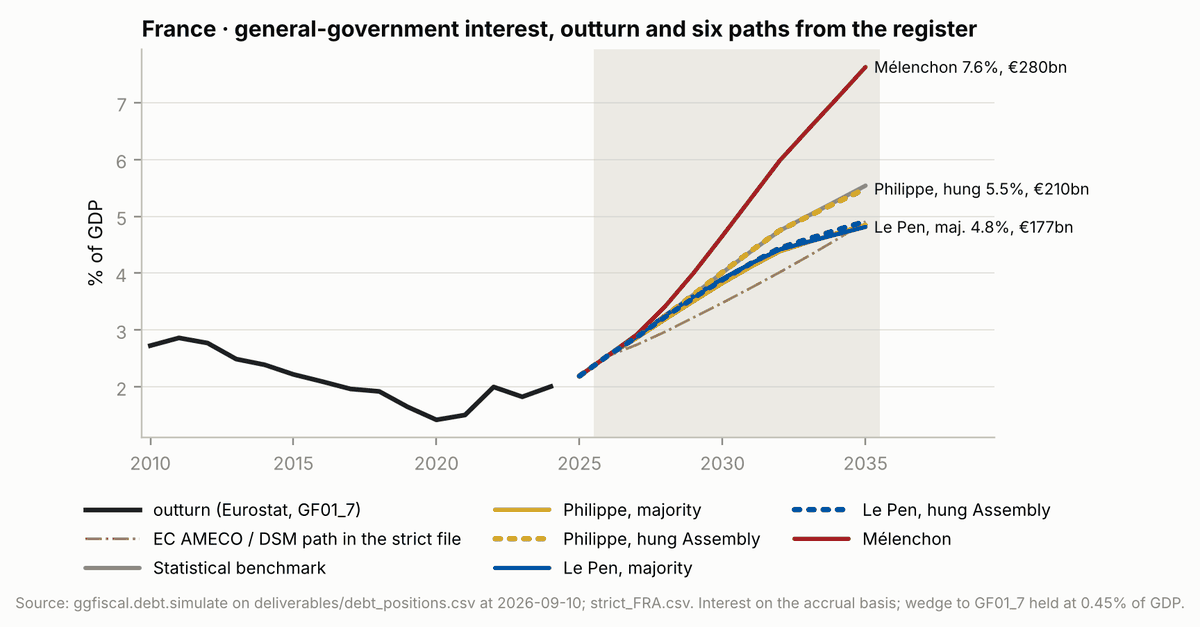

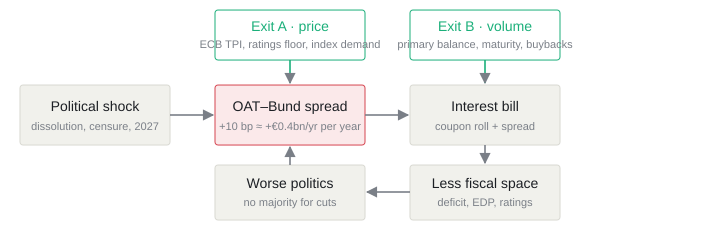

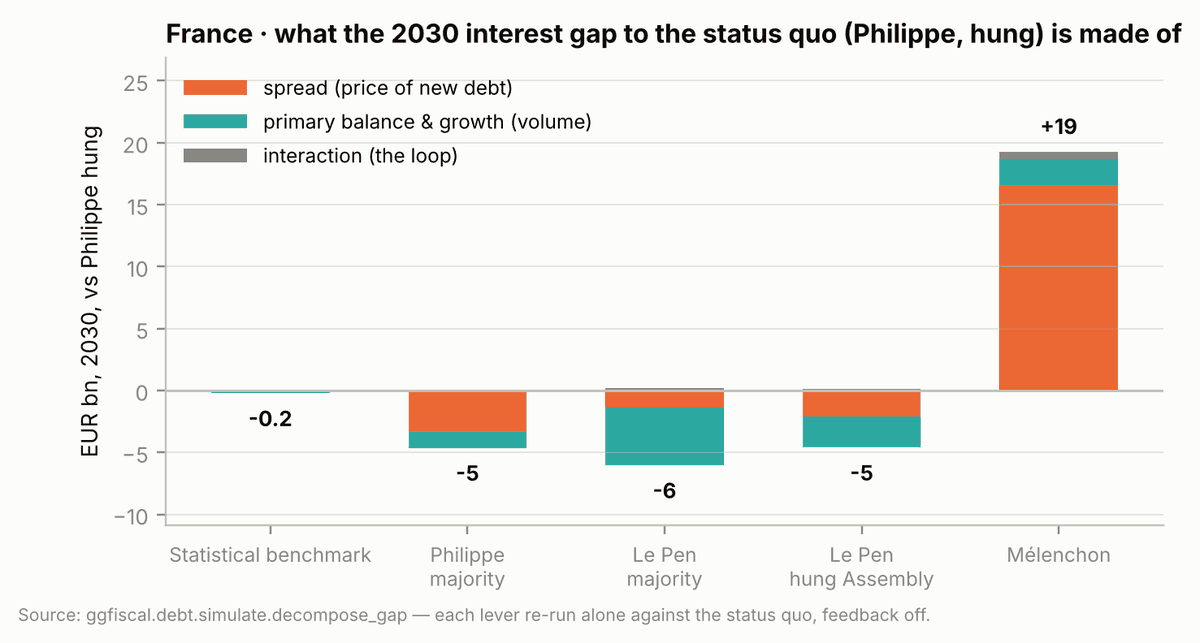

In [4]:
section("s2")

## 3. The shortening stock

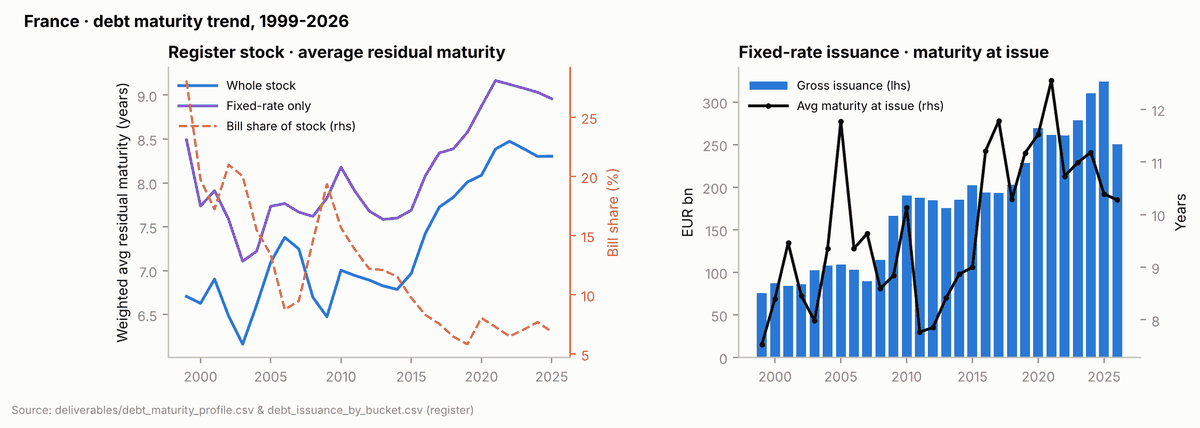

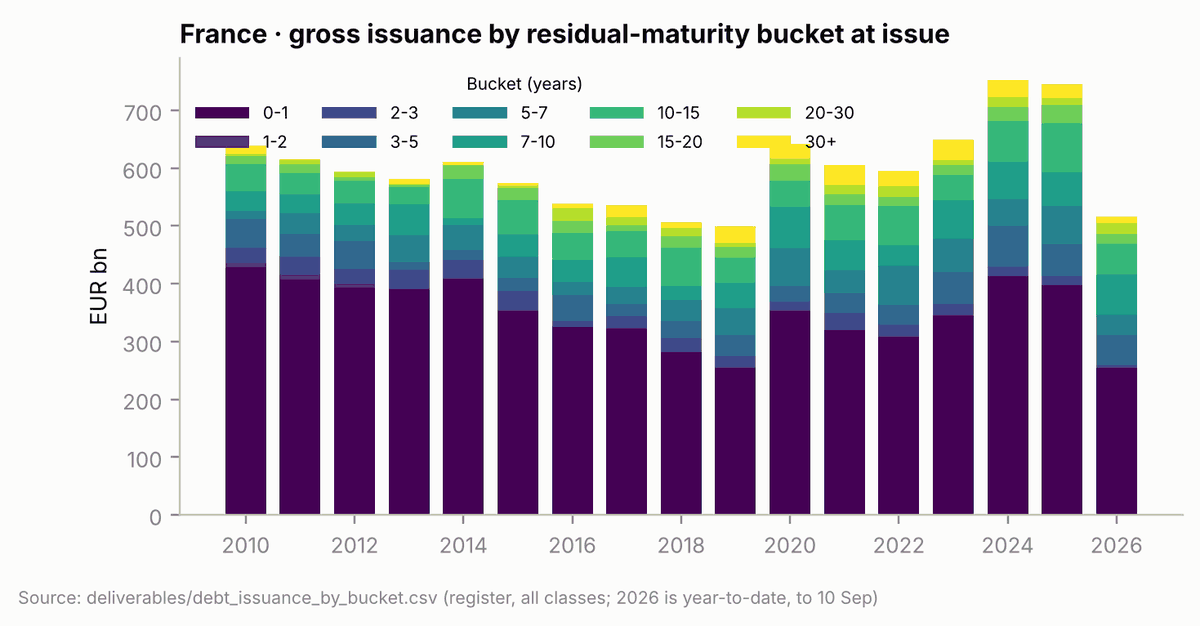

In [5]:
section("s3")

## 4. Who holds it, and how rate-sensitive they are

Holder (end-Q1 2026),Share of negotiable debt,≈ EUR bn,"MTM loss per 100 bp, EUR bn",Behaviour when rates rise
Non-residents,57.5%,"1,670",80,"About half euro-area. The non-euro half (Japan, Asian reserve managers) sold €30bn in 2024 and is the swing buyer now; the group that leaves first and returns last."
"Other French residents, incl. Banque de France (Eurosystem: €488bn at end-June 2026)",20.6%,598,29,"The Eurosystem is a passive seller: ≈€10bn a month of run-off, no reinvestment. The TPI is the only conditional buyer."
French banks,10.5%,305,15,"Mostly amortised cost, held for liquidity ratios; insensitive to mark-to-market, sensitive to ratings, repo haircuts and the sovereign-bank loop."
French insurers,9.6%,279,13,"Euro-fund books, long duration (above-average loss). Buy on inflows; inflows reverse with rates and with any assurance-vie or wealth-tax proposal."
French funds (OPCVM),1.8%,52,3,"Money-market funds in bills; price-insensitive, size-limited."


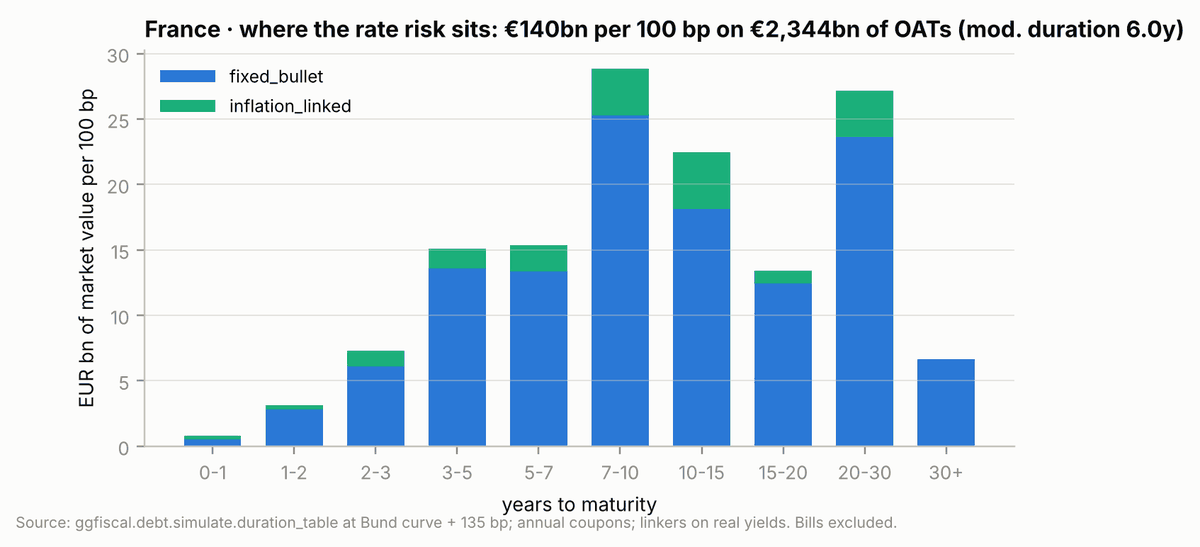

In [6]:
section("s4")

## 5. The 2027 map: Philippe, Le Pen, Mélenchon

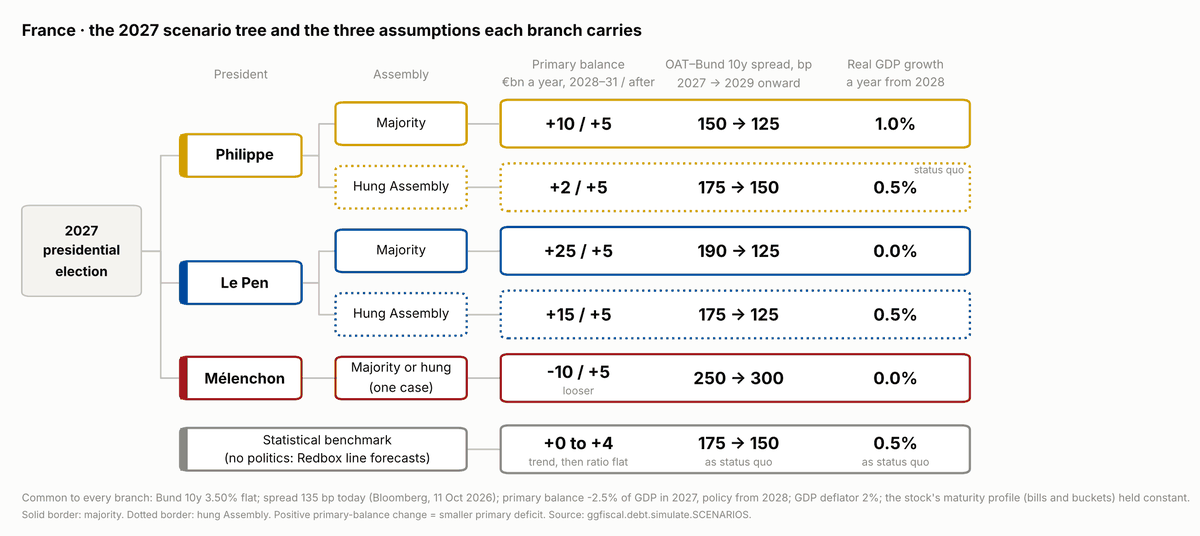

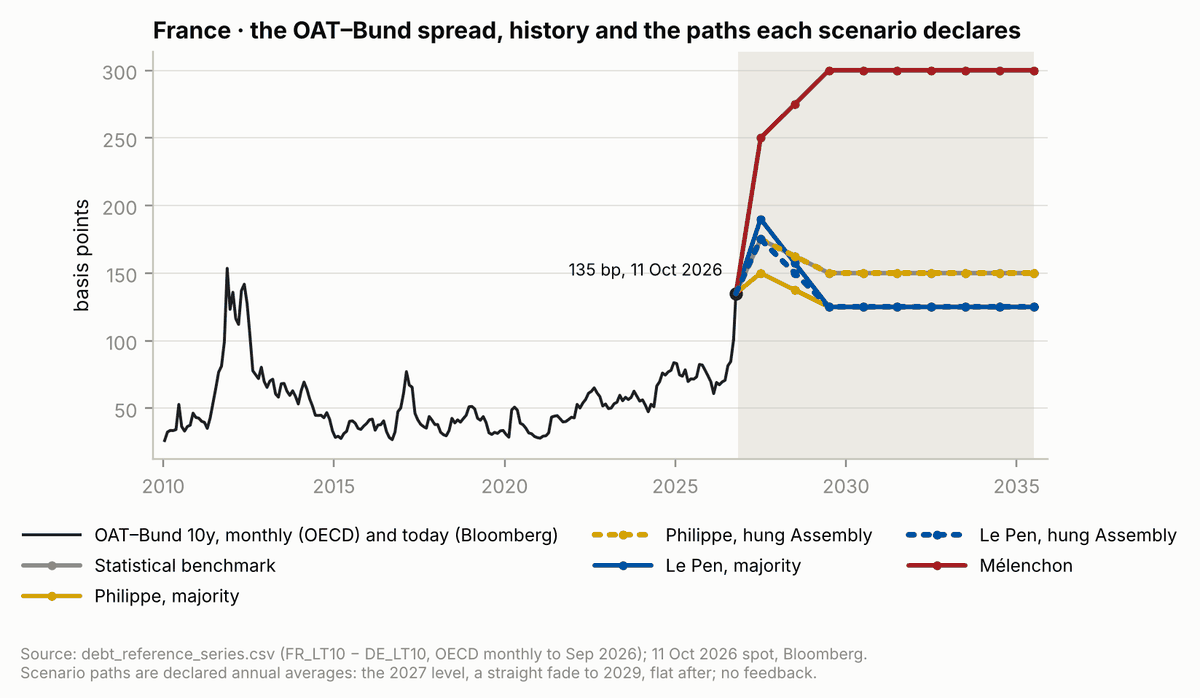

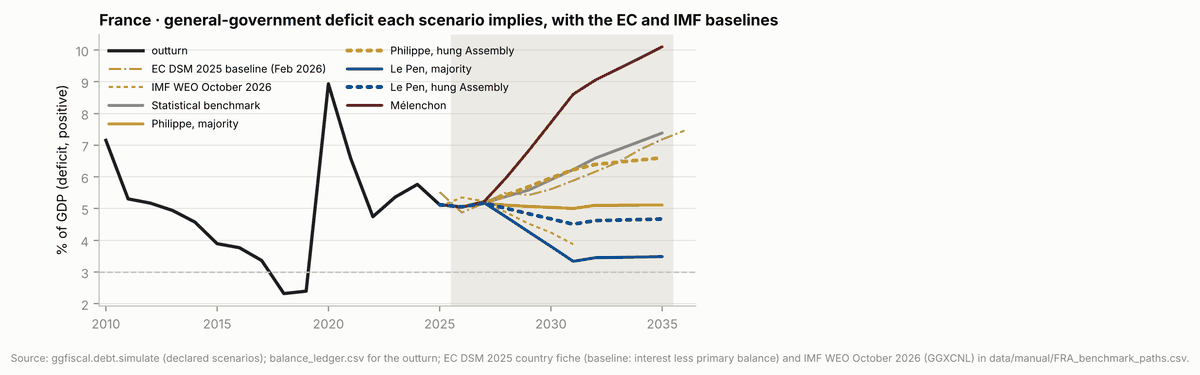

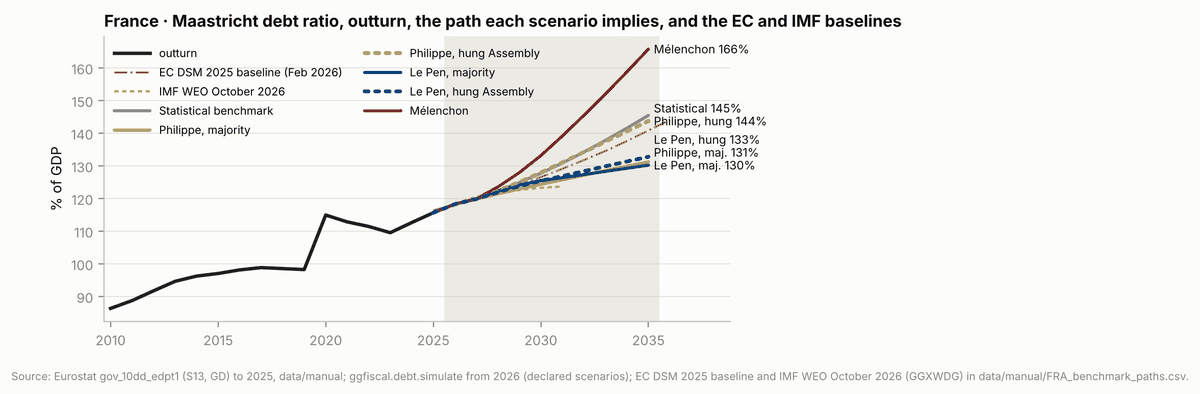

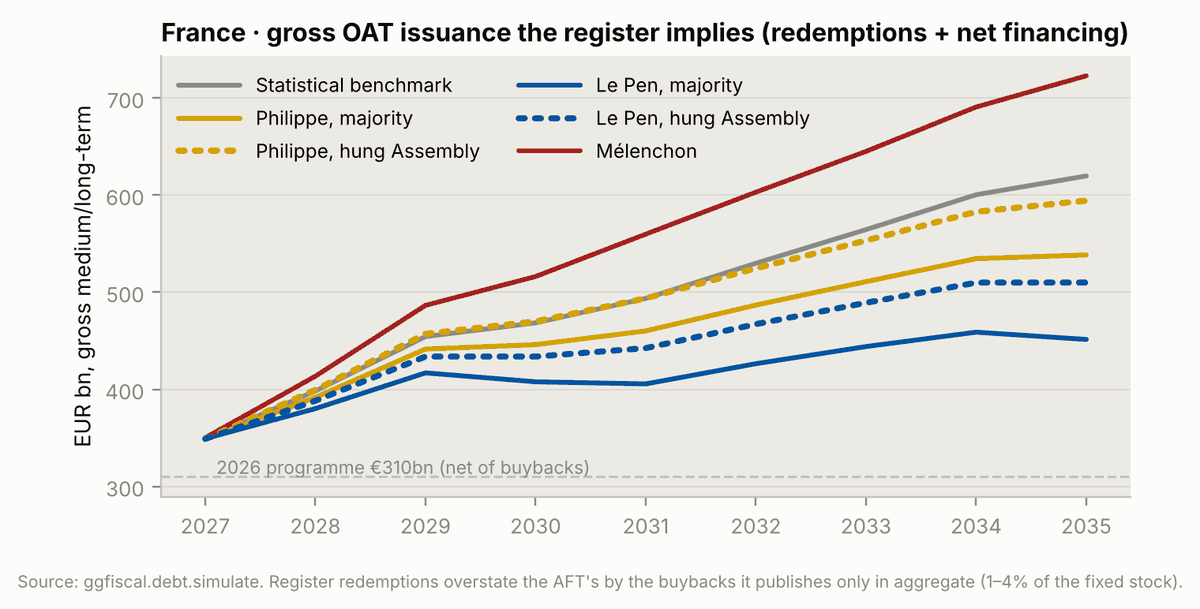

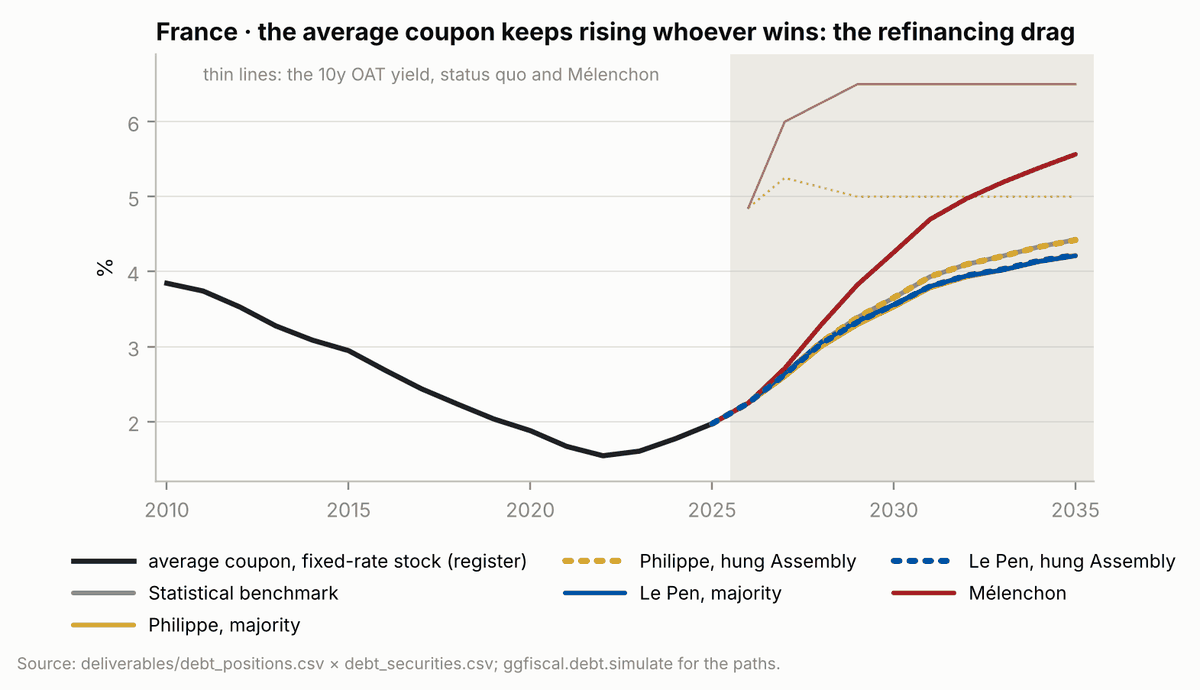

In [7]:
section("s5")

## 6. Other things that matter in the room

In [8]:
section("s6")

## 7. The other side of the balance sheet: cash, net debt and what could be sold

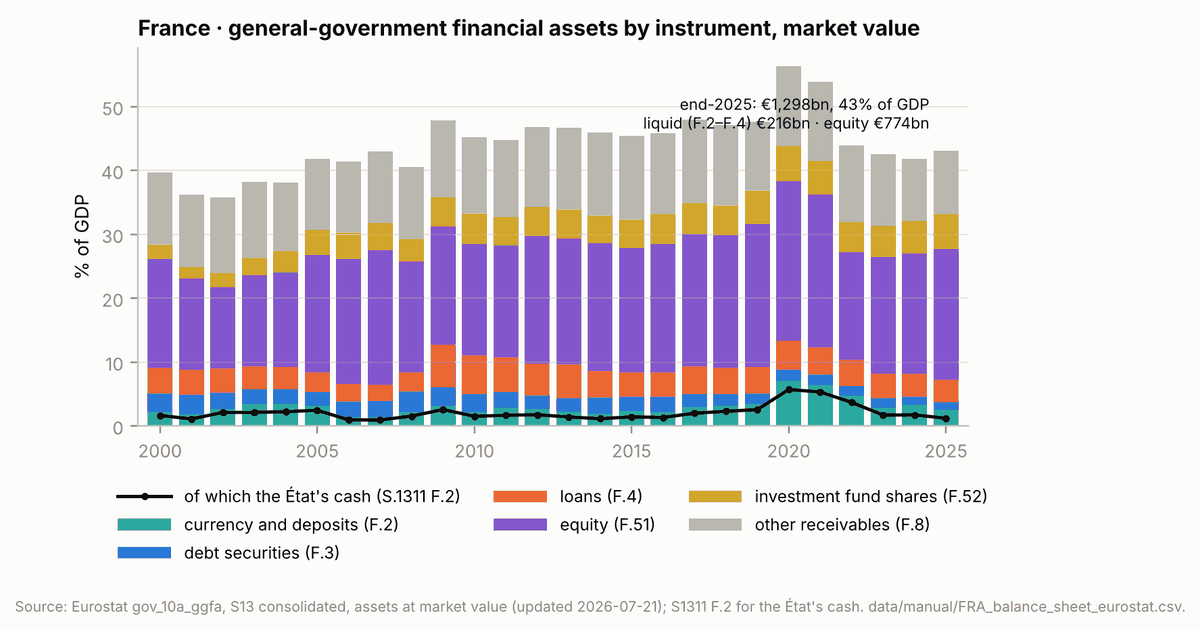

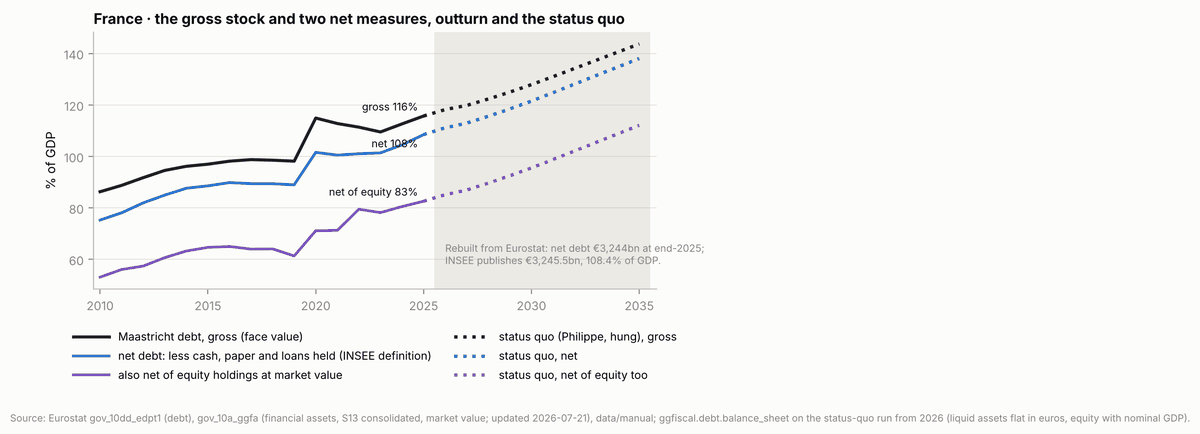

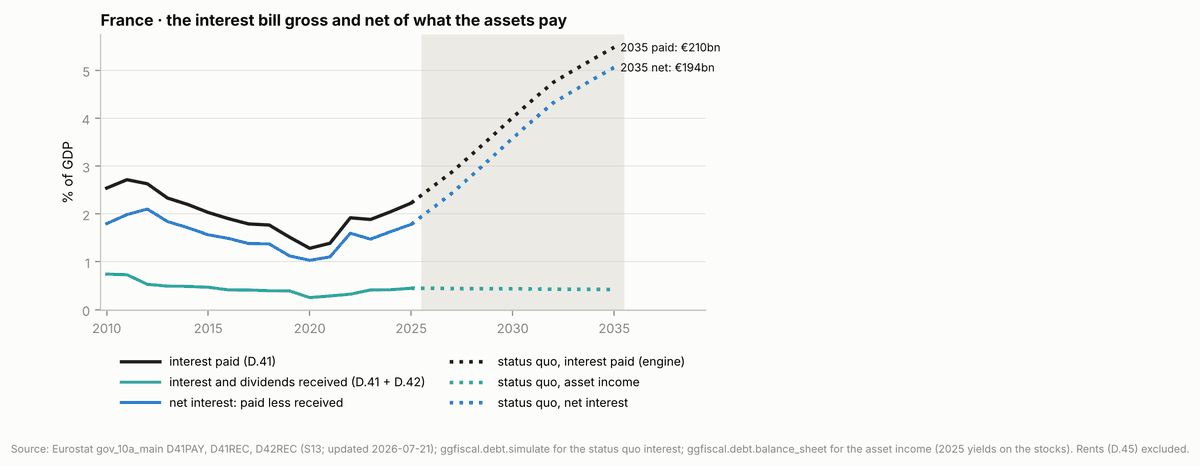

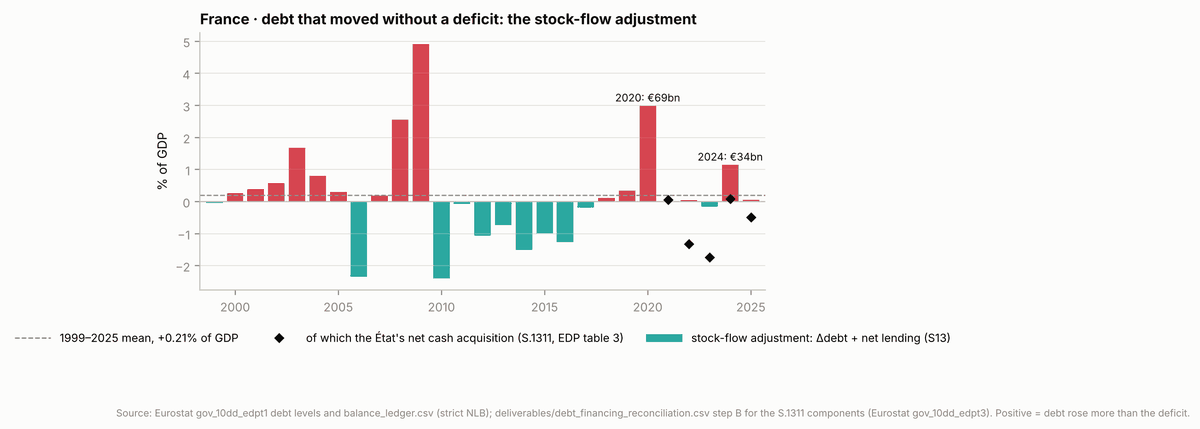

Year,Cash and deposits,Securities and loans,Equity injections,Other receivables,"Issuance premia, accruals",Other,État SFA
2021,+1.6,+1.8,+3.0,+11.9,-4.3,+19.1,+33.1
2022,-35.1,+1.9,-5.7,+9.6,+26.5,-4.2,-7.0
2023,-49.4,-2.6,+8.9,+3.3,+29.8,-14.1,-24.1
2024,+2.4,-2.1,-0.3,+4.4,+17.1,-12.9,+8.6
2025,-14.7,-2.7,+3.5,+6.6,+14.4,-12.9,-5.7


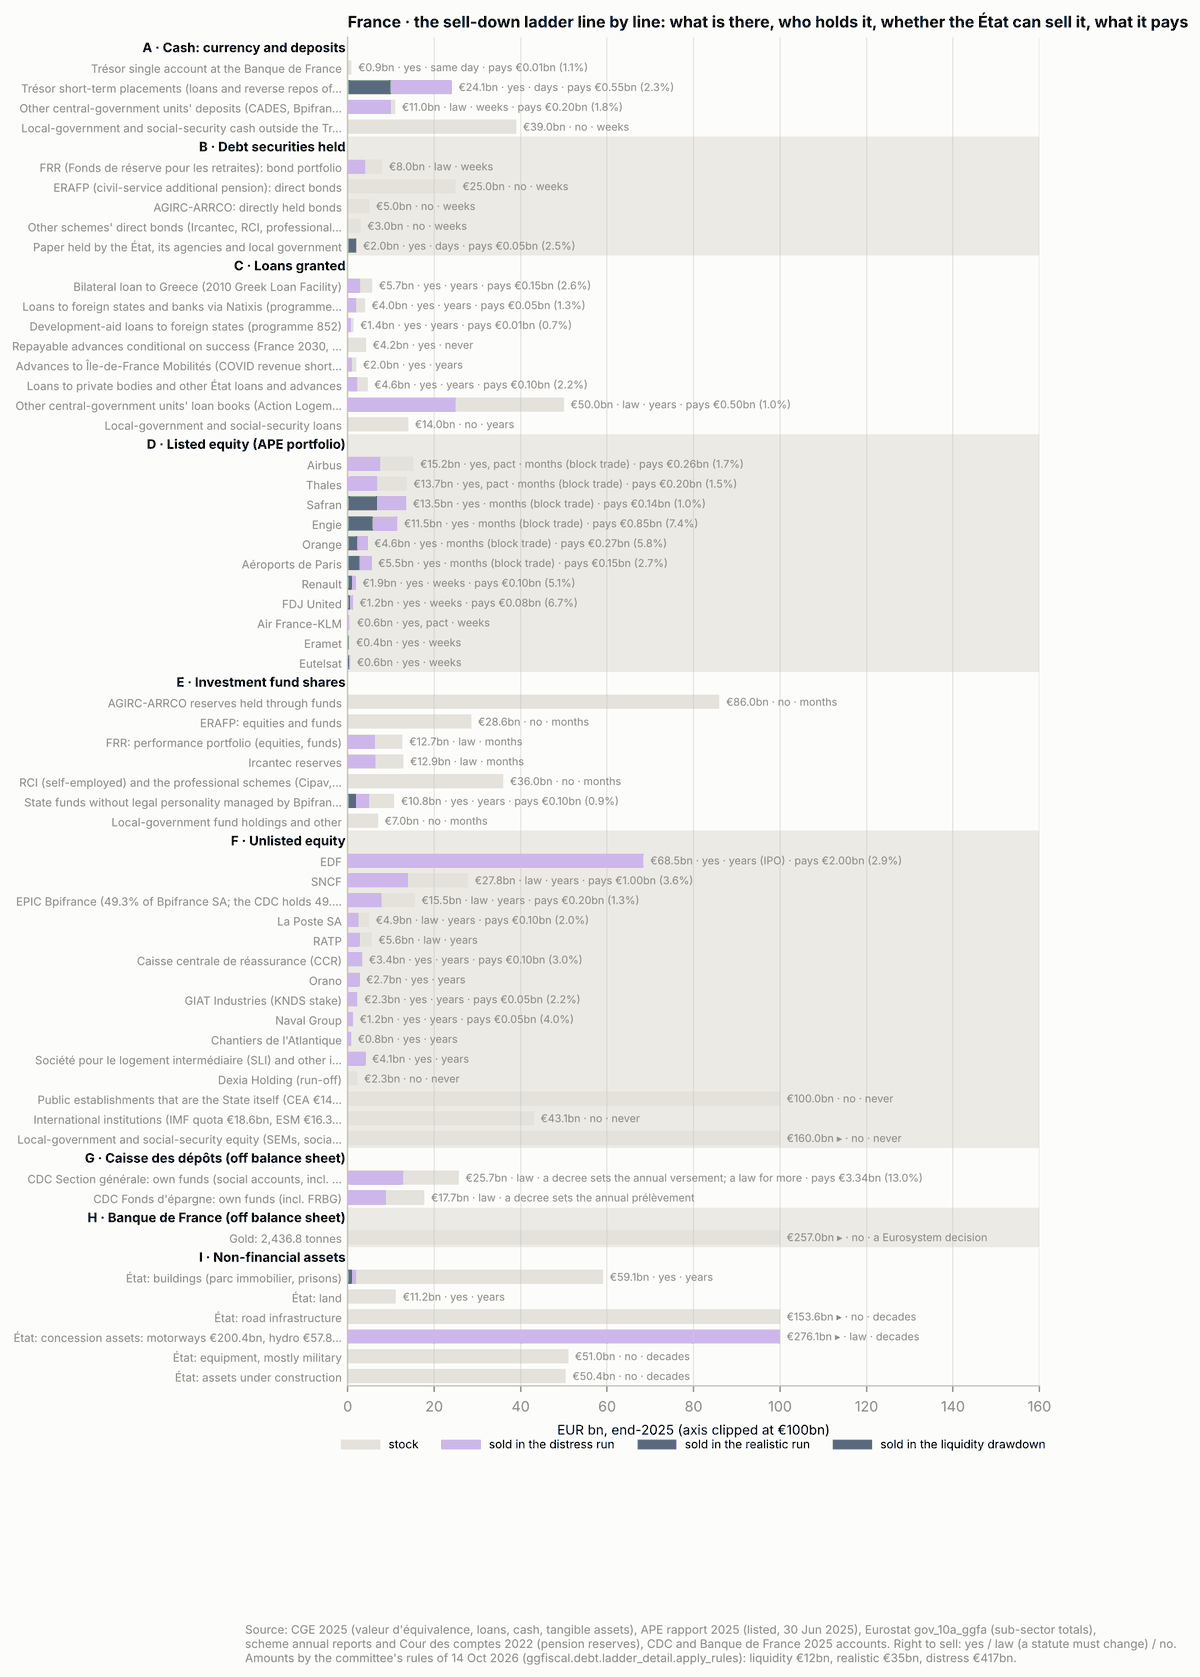

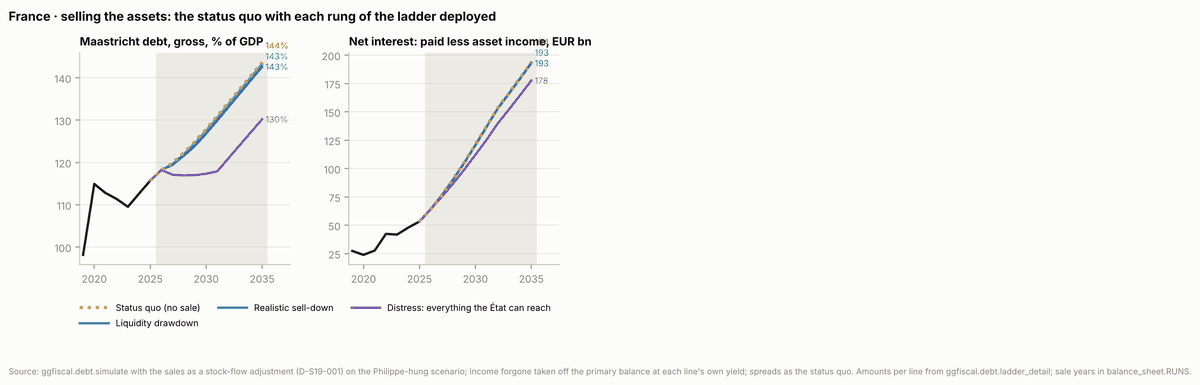

Run,"Sold, €bn",When,"Debt 2030, %","Debt 2035, %","Net debt 2035, %","Interest saved 2035, €bn","Income lost 2035, €bn","Net interest 2035, €bn","Deficit 2035, %"
Status quo (no sale),-0,–,128,144,138,0,0,194,6.6
Liquidity drawdown,12,2027–2028,128,143,138,1,0,193,6.6
Realistic sell-down,35,2027–2029,127,143,137,2,1,193,6.6
Distress: everything the État can reach,417,2027–2031,117,130,126,24,8,178,6.2


In [9]:
section("s9")

## 8. The retirement age: what a year of it costs, line by line, and when

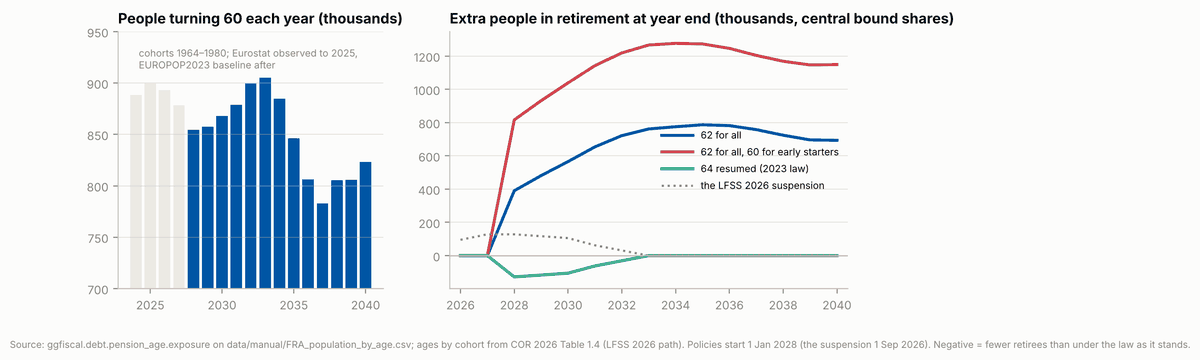

Year,62 for all: cohort-years,of steady state,"extra retirees, k","cost, €bn",with 60: cohort-years,of steady state,"extra retirees, k","cost, €bn","64 resumed: retirees, k","saving, €bn"
2028,0.85,49%,390,10.9,1.46,59%,816,23.5,-128,3.5
2029,1.06,61%,481,13.9,1.69,69%,932,27.2,-117,2.8
2030,1.19,69%,566,16.0,1.87,76%,"1,039",30.3,-106,3.0
2031,1.33,78%,654,18.3,2.05,83%,"1,143",33.8,-62,2.2
2032,1.50,87%,722,20.9,2.22,90%,"1,219",36.9,-31,2.6
2033,1.70,99%,762,24.2,2.43,99%,"1,266",40.8,0,0.0
2034,1.72,100%,775,25.0,2.46,100%,"1,277",42.0,0,0.0
2035,1.75,102%,787,25.9,2.47,101%,"1,273",42.9,0,0.0
2036,1.76,102%,782,26.5,2.45,100%,"1,246",43.2,0,0.0


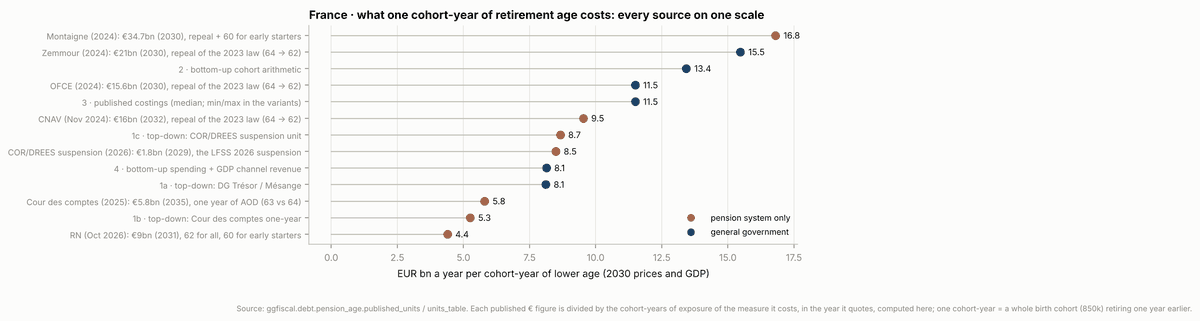

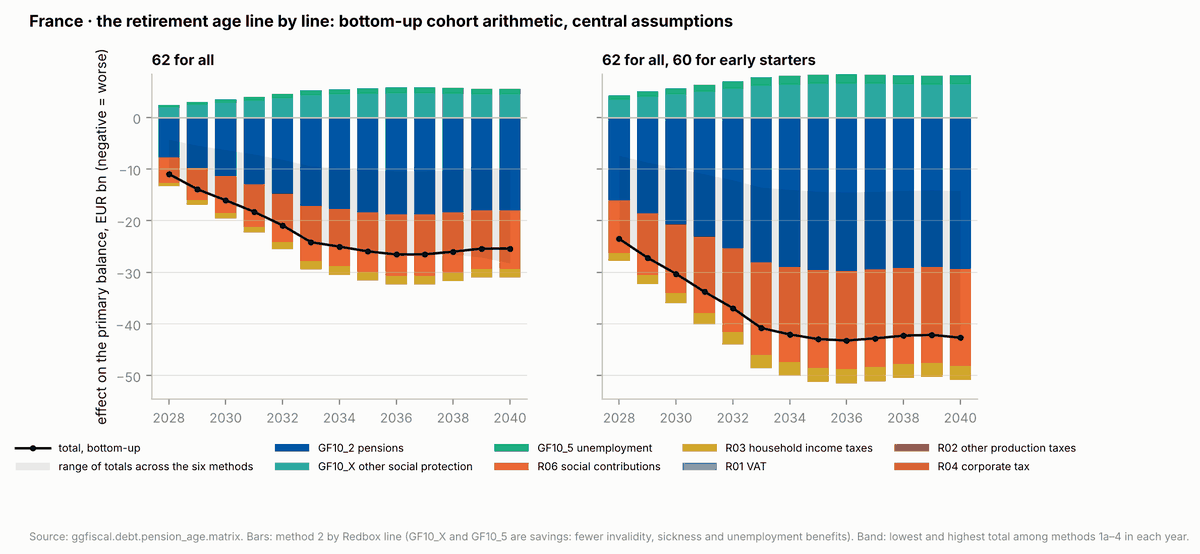

Line,Side,2028,2030,2032,2035
GF10_2 · Old age (pensions),expenditure,+7.7 (+3.0 to +7.7),+11.4 (+4.5 to +11.4),+14.8 (+5.8 to +14.8),+18.4 (+7.2 to +18.4)
GF10_X · Social protection ex old age and unemployment,expenditure,-1.9 (-2.2 to +0.0),-2.8 (-3.2 to +0.0),-3.7 (-4.3 to +0.0),-4.6 (-5.4 to +0.0)
GF10_5 · Unemployment,expenditure,-0.5 (-0.5 to +0.0),-0.7 (-0.8 to +0.0),-0.9 (-1.1 to +0.0),-1.1 (-1.3 to +0.0)
R06 · Net social contributions,revenue,-4.9 (-4.9 to -0.2),-7.2 (-7.2 to -0.7),-9.3 (-9.3 to -1.5),-11.6 (-11.6 to -2.9)
R03 · Taxes on household income,revenue,-0.7 (-0.7 to +0.0),-1.0 (-1.0 to +0.0),-1.3 (-2.0 to +0.0),-1.7 (-3.5 to +0.0)
R01 · Value added tax,revenue,+0.0 (-0.3 to +0.0),+0.0 (-0.8 to +0.0),+0.0 (-1.5 to +0.0),+0.0 (-2.7 to +0.0)
R02 · Other taxes on production and imports,revenue,+0.0 (-0.3 to +0.0),+0.0 (-0.9 to +0.0),+0.0 (-1.8 to +0.0),+0.0 (-3.2 to +0.0)
R04 · Taxes on corporate income,revenue,+0.0 (-0.1 to +0.0),+0.0 (-0.3 to +0.0),+0.0 (-0.6 to +0.0),+0.0 (-1.1 to +0.0)
"Primary balance, all lines",net,-10.9 (-10.9 to -4.3),-16.0 (-16.0 to -6.3),-20.9 (-20.9 to -8.2),-25.9 (-25.9 to -10.1)
"Primary balance, bottom-up, low to high assumptions",net,-1.9 to -19.0,-8.1 to -27.8,-10.5 to -36.2,-13.0 to -44.9


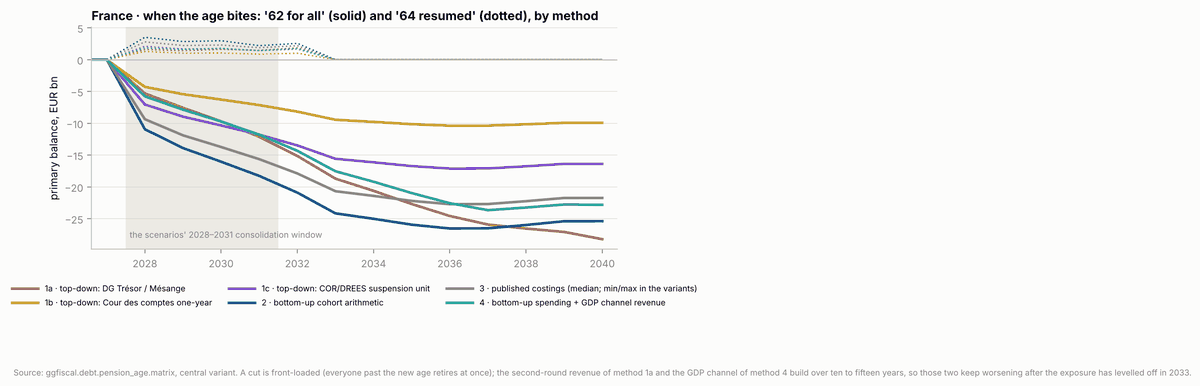

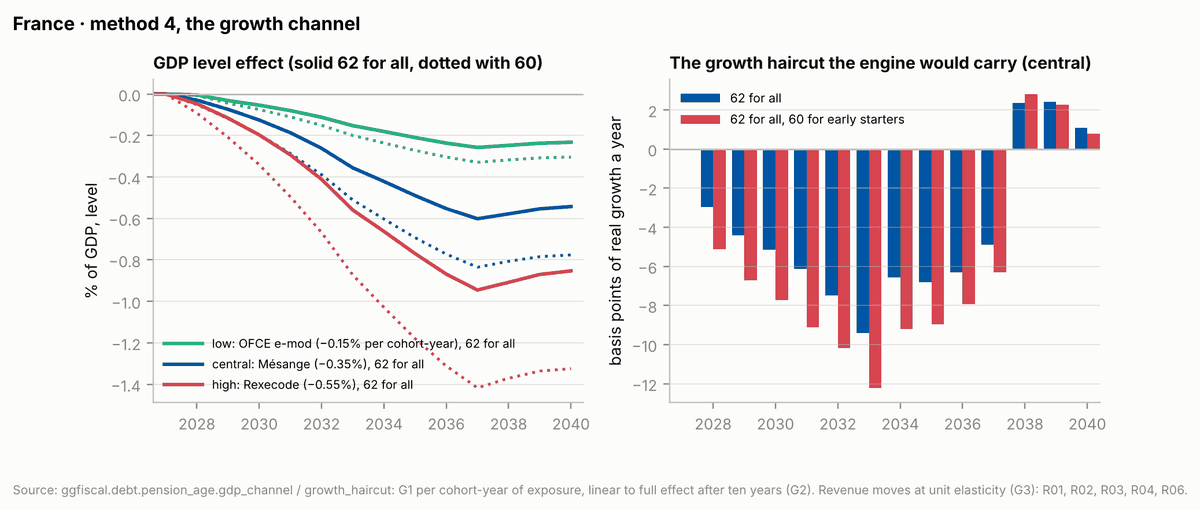

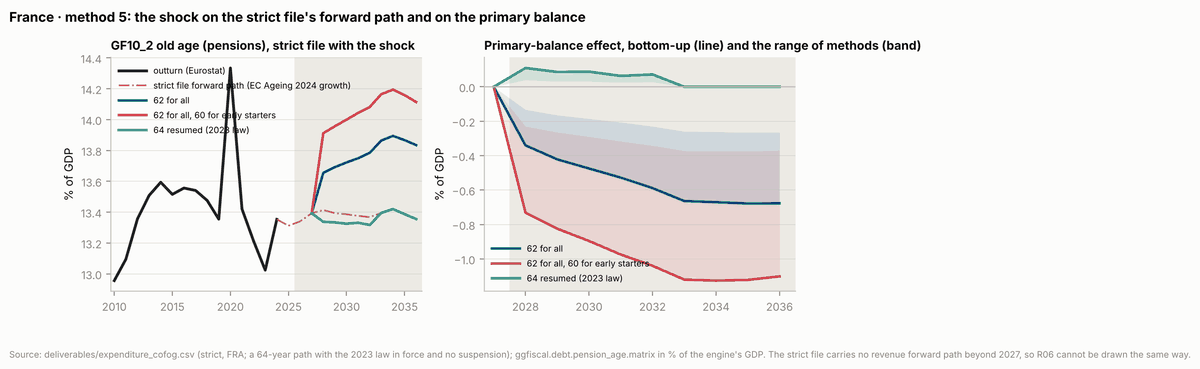

In [10]:
section("s10")

## 10. Method, sources and caveats

In [11]:
section("s8")

Item,Value,Source or reason
Register,"Positions at 10 Sep 2026, 106 bonds and 30 bill lines outstanding",debt_positions (office snapshot)
Nominal GDP,"2025 €2,979bn; 2026 €3,056bn; 2027 €3,151bn; then the scenario's real growth plus a 2% deflator",ledger; strict_FRA (EC AMECO); declared
Primary balance,"−3.1 (2025), −2.7 (2026), −2.5 (2027) % of GDP in every scenario; from 2028 the previous year in €bn plus the scenario's change, or for the statistical benchmark the benchmark's change in pp of GDP (section 5 tables)",declared; committee 11 Oct 2026
Bund curve,"3m 2.50, 2y 3.00, 5y 3.25, 10y 3.50, 30y 3.85 %, flat through 2035",10y declared by the committee (DE_LT10 Sep 2026 avg 3.47); 3m EA_MM_3M Aug 2026; 2y–30y keep the previous slope to the 10y
Spread today,"135 bp on 11 Oct 2026, applied to the rest of 2026 in every scenario",Bloomberg (ext); the bundle's OECD monthly series ends at 101 bp in September 2026
Spread term structure,0.15 / 0.45 / 0.75 / 1.00 / 1.15 × the 10y spread at 3m / 2y / 5y / 10y / 30y,declared
Issuance rule,"Constant maturity profile (bills 7.6% of the stock, bonds by bucket at their end-2026 shares), tranches at the AFT's own 2025 residual maturity at issue per bucket; the same in every scenario",debt_issuance_by_bucket; AFT 2026 programme
Inflation (uplift),"2.0% a year, linkers 7% of new issuance at the real yield",declared
Deficit financed by negotiable debt,0.90,"Δ(F.31+F.32) / −NLB, 2015–2025, from the bundle"
Wedge to GF01_7,0.45% of GDP (€13.4bn in 2025),"GF01_7 less register accrued (D.41) interest, 2025"


## The scenario results as data

Every scenario-year the engine produced, at the years the note quotes.

In [12]:
res = pd.read_csv(FIG / "scenarios_FRA.csv")
cols = ["label", "year", "spread_bp", "oat_10y_pct", "primary_balance_pct", "gg_interest_bn",
        "gg_interest_pct_gdp", "deficit_pct_gdp", "debt_pct_gdp", "mlt_gross_issuance_bn"]
res[res.year.isin([2027, 2028, 2030, 2032, 2035])][cols].round(1).set_index(["label", "year"])

spread_bp  oat_10y_pct  primary_balance_pct  \
label                   year                                                
Statistical benchmark   2027      175.0          5.2                 -2.5   
                        2028      162.5          5.1                 -2.3   
                        2030      150.0          5.0                 -2.1   
                        2032      150.0          5.0                 -2.0   
                        2035      150.0          5.0                 -2.0   
Philippe, majority      2027      150.0          5.0                 -2.5   
                        2028      137.5          4.9                 -2.1   
                        2030      125.0          4.8                 -1.4   
                        2032      125.0          4.8                 -0.9   
                        2035      125.0          4.8                 -0.5   
Philippe, hung Assembly 2027      175.0          5.2                 -2.5   
                        2028      162.5          5.1                 -2.4   
                        2030      150.0          5.0                 -2.1   
                        2032      150.0          5.0                 -1.8   
                        2035      150.0          5.0                 -1.3   
Le Pen, majority        2027      190.0          5.4                 -2.5   
                        2028      157.5          5.1                 -1.7   
                        2030      125.0          4.8                 -0.1   
                        2032      125.0          4.8                  0.8   
                        2035      125.0          4.8                  1.1   
Le Pen, hung Assembly   2027      175.0          5.2                 -2.5   
                        2028      150.0          5.0                 -2.0   
                        2030      125.0          4.8                 -1.0   
                        2032      125.0          4.8                 -0.4   
                        2035      125.0          4.8                  0.0   
Mélenchon               2027      250.0          6.0                 -2.5   
                        2028      275.0          6.2                 -2.8   
                        2030      300.0          6.5                 -3.3   
                        2032      300.0          6.5                 -3.3   
                        2035      300.0          6.5                 -2.7   

                              gg_interest_bn  gg_interest_pct_gdp  \
label                   year                                        
Statistical benchmark   2027            90.2                  2.9   
                        2028           104.5                  3.2   
                        2030           135.6                  4.0   
                        2032           168.6                  4.7   
                        2035           212.0                  5.5   
Philippe, majority      2027            89.7                  2.9   
                        2028           103.1                  3.2   
                        2030           131.2                  3.8   
                        2032           159.6                  4.4   
                        2035           193.1                  4.8   
Philippe, hung Assembly 2027            90.2                  2.9   
                        2028           104.5                  3.2   
                        2030           135.8                  4.0   
                        2032           168.7                  4.8   
                        2035           209.9                  5.5   
Le Pen, majority        2027            90.5                  2.9   
                        2028           104.3                  3.3   
                        2030           129.9                  3.9   
                        2032           153.0                  4.4   
                        2035           177.0                  4.8   
Le Pen, hung Assembly   2027            90.2   

## The balance-sheet runs as data

The sell-down ladder line by line (what is there at end-2025 and how much each run sells),
then every run-year of section 7 (status quo, liquidity, realistic, distress): gross and net debt, the interest bill, the
asset income and the net interest, on the status-quo scenario.

The ladder line by line (D-S19-002/003): valuation on the CGE, the APE and Eurostat, who holds
it, whether the État can sell it, what it pays the État, and the amount each run sells under the
committee's rules of 14 October 2026 (the `rule` column). These amounts drive the runs below.

In [13]:
det = pd.read_csv(FIG / "ladder_detail_FRA.csv", keep_default_na=False)
pd.set_option("display.max_rows", 100); pd.set_option("display.max_colwidth", 70)
det[~det.reference_only][["group", "line", "holder", "stock_bn", "can_sell", "liquidity", "income_bn", "yield_pct",
                          "sold_liquidity_bn", "sold_realistic_bn", "sold_distress_bn", "rule"]].round(2).set_index(["group", "line"])

holder  \
group    line                                                                                                                 
cash     Trésor single account at the Banque de France                                                           État (AFT)   
         Trésor short-term placements (loans and reverse repos of État cash)                                     État (AFT)   
         Other central-government units' deposits (CADES, Bpifrance EPIC, ag...                                        ODAC   
         Local-government and social-security cash outside the Trésor                                        S.1313, S.1314   
paper    FRR (Fonds de réserve pour les retraites): bond portfolio                                              FRR, S.1314   
         ERAFP (civil-service additional pension): direct bonds                                               ERAFP, S.1314   
         AGIRC-ARRCO: directly held bonds                                                               AGIRC-ARRCO, S.1314   
         Other schemes' direct bonds (Ircantec, RCI, professional schemes)                                           S.1314   
         Paper held by the État, its agencies and local government                                           S.1311, S.1313   
loans    Bilateral loan to Greece (2010 Greek Loan Facility)                                                           État   
         Loans to foreign states and banks via Natixis (programme 851, expor...                                        État   
         Development-aid loans to foreign states (programme 852)                                                       État   
         Repayable advances conditional on success (France 2030, PIA, aerosp...                                        État   
         Advances to Île-de-France Mobilités (COVID revenue shortfall)                                                 État   
         Loans to private bodies and other État loans and advances                                                     État   
         Other central-government units' loan books (Action Logement Service...                                        ODAC   
         Local-government and social-security loans                                                          S.1313, S.1314   
listed   Airbus                                                                                      État 10.83% via SOGEPA   
         Thales                                                                                         État 26.60% via TSA   
         Safran                                                                                                 État 11.20%   
         Engie                                                                                                  État 23.64%   
         Orange                                                                  État 13.39% (Bpifrance holds another 9.6%)   
         Aéroports de Paris                                                                                     État 50.63%   
         Renault                                                                                                État 15.01%   
         FDJ United                                                                                             État 20.46%   
         Air France-KLM                                                                                         État 27.98%   
         Eramet                                                                                État 27.13% via FSI Equation   
         Eutelsat                                                                          État 29.65% (acquired July 2025)   
funds    AGIRC-ARRCO reserves held through funds                                                        AGIRC-ARRCO, S.1314   
         ERAFP: equities and funds                                                                            ERAFP, S.1314   
         FRR: performance portfolio (equities, funds)

In [14]:
sd = pd.read_csv(FIG / "selldown_FRA.csv")
cols = ["run_label", "year", "sfa_bn", "debt_pct_gdp", "net_debt_pct_gdp", "net_fin_debt_pct_gdp", "gg_interest_bn",
        "asset_income_bn", "net_interest_bn", "deficit_pct_gdp", "primary_balance_pct"]
sd[sd.year.isin([2027, 2030, 2035])][cols].round(1).set_index(["run_label", "year"])

sfa_bn  debt_pct_gdp  \
run_label                               year                         
Status quo (no sale)                    2027     0.0         119.8   
                                        2030     0.0         127.9   
                                        2035     0.0         143.7   
Liquidity drawdown                      2027    -6.0         119.6   
                                        2030     0.0         127.5   
                                        2035     0.0         143.3   
Realistic sell-down                     2027   -11.5         119.4   
                                        2030     0.0         126.8   
                                        2035     0.0         142.6   
Distress: everything the État can reach 2027   -83.5         117.1   
                                        2030   -83.5         117.3   
                                        2035     0.0         130.2   

                                              net_debt_pct_gdp  \
run_label                               year                     
Status quo (no sale)                    2027             112.9   
                                        2030             121.5   
                                        2035             138.0   
Liquidity drawdown                      2027             112.9   
                                        2030             121.5   
                                        2035             138.0   
Realistic sell-down                     2027             112.7   
                                        2030             120.8   
                                        2035             137.3   
Distress: everything the État can reach 2027             110.7   
                                        2030             112.7   
                                        2035             126.5   

                                              net_fin_debt_pct_gdp  \
run_label                               year                         
Status quo (no sale)                    2027                  87.0   
                                        2030                  95.5   
                                        2035                 112.1   
Liquidity drawdown                      2027                  87.0   
                                        2030                  95.5   
                                        2035                 112.0   
Realistic sell-down                     2027                  86.9   
                                        2030                  95.5   
                                        2035                 112.0   
Distress: everything the État can reach 2027                  86.0   
                                        2030                  91.7   
                                        2035                 106.7   

                                              gg_interest_bn  asset_income_bn  \
run_label                               year                                    
Status quo (no sale)                    2027            90.2             13.8   
                                        2030           135.8             14.7   
                                        2035           209.9             16.1   
Liquidity drawdown                      2027            90.1             13.7   
                                        2030           135.2             14.4   
                                        2035           209.1             15.8   
Realistic sell-down                     2027            89.9             13.6   
                                        2030           134.1             13.6   
                                        2035           207.9             15.0   
Distress: everything the État can reach 2027            88.2             13.1   
                                        2030           121.5              9.4   
                                        2035           186.1              8.5   

                        

## The retirement-age matrix as data

The impact by method, line and year (`pension_age_matrix.csv`), the exposure behind it and the assumptions register, as section 8 uses them. Positive expenditure = more spending, positive revenue = more revenue; `balance_bn` is the effect on the primary balance.

In [15]:
pm = pd.read_csv(FIG / "pension_age_matrix.csv")
pm[(pm.variant == "central") & (pm.year.isin([2028, 2030, 2032, 2035])) & (pm.policy.isin(["p62", "p60"]))]\
    .pivot_table(index=["policy", "method", "line_code"], columns="year", values="balance_bn").round(1)

year                           2028  2030  2032  2035
policy method       line_code                        
p60    m1_cor       GF10_2     -8.7 -11.5 -14.3 -16.9
                    GF10_5      0.0   0.0   0.0   0.0
                    GF10_X      0.0   0.0   0.0   0.0
                    R01         0.0   0.0   0.0   0.0
                    R02         0.0   0.0   0.0   0.0
                    R03         0.0   0.0   0.0   0.0
                    R04         0.0   0.0   0.0   0.0
                    R06        -3.5  -4.6  -5.8  -6.8
       m1_cour      GF10_2     -5.3  -7.0  -8.7 -10.2
                    GF10_5      0.0   0.0   0.0   0.0
                    GF10_X      0.0   0.0   0.0   0.0
                    R01         0.0   0.0   0.0   0.0
                    R02         0.0   0.0   0.0   0.0
                    R03         0.0   0.0   0.0   0.0
                    R04         0.0   0.0   0.0   0.0
                    R06        -2.1  -2.8  -3.5  -4.1
       m1_tresor    GF10_2     -9.4 -12.6 -15.8 -18.9
                    GF10_5      0.9   1.3   1.6   1.9
                    GF10_X      3.8   5.0   6.3   7.6
                    R01        -0.4  -1.2  -2.2  -3.8
                    R02        -0.5  -1.4  -2.7  -4.5
                    R03        -0.6  -1.6  -3.0  -5.0
                    R04        -0.2  -0.5  -0.9  -1.5
                    R06        -2.7  -4.1  -5.8  -7.8
       m2_bottom_up GF10_2    -16.0 -20.7 -25.3 -29.5
                    GF10_5      1.0   1.2   1.5   1.8
                    GF10_X      3.3   4.4   5.5   6.5
                    R01         0.0   0.0   0.0   0.0
                    R02         0.0   0.0   0.0   0.0
                    R03        -1.5  -1.9  -2.4  -2.8
                    R04         0.0   0.0   0.0   0.0
                    R06       -10.3 -13.3 -16.2 -18.9
       m3_published GF10_2    -11.1 -14.7 -18.2 -21.5
                    GF10_5      0.7   0.9   1.1   1.3
                    GF10_X      2.4   3.1   3.9   4.6
                    R01         0.0   0.0   0.0   0.0
                    R02         0.0   0.0   0.0   0.0
                    R03        -1.0  -1.4  -1.7  -2.0
                    R04         0.0   0.0   0.0   0.0
                    R06        -7.1  -9.4 -11.7 -13.8
       m4_growth    GF10_2    -16.0 -20.7 -25.3 -29.5
                    GF10_5      1.0   1.2   1.5   1.8
                    GF10_X      3.3   4.4   5.5   6.5
                    R01        -0.1  -0.5  -1.0  -1.9
                    R02        -0.1  -0.6  -1.2  -2.2
                    R03        -0.2  -0.6  -1.3  -2.5
                    R04        -0.0  -0.2  -0.4  -0.8
                    R06        -0.3  -1.1  -2.3  -4.4
p62    m1_cor       GF10_2     -5.0  -7.4  -9.6 -11.9
                    GF10_5      0.0   0.0   0.0   0.0
                    GF10_X      0.0   0.0   0.0   0.0
                    R01         0.0   0.0   0.0   0.0
                    R02         0.0   0.0   0.0   0.0
                    R03         0.0   0.0   0.0   0.0
                    R04         0.0   0.0   0.0   0.0
                    R06        -2.0  -3.0  -3.9  -4.8
       m1_cour      GF10_2     -3.0  -4.5  -5.8  -7.2
                    GF10_5      0.0   0.0   0.0   0.0
                    GF10_X      0.0   0.0   0.0   0.0
                    R01         0.0   0.0   0.0   0.0
                    R02         0.0   0.0   0.0   0.0
                    R03         0.0   0.0   0.0   0.0
                    R04         0.0   0.0   0.0   0.0
                    R06        -1.2  -1.8  -2.4  -2.9
       m1_tresor    GF10_2     -5.5  -8.1 -10.6 -13.4
                    GF10_5      0.5   0.8   1.1   1.3
                    GF10_X      2.2   3.2   4.3   5.4
                    R01        -0.3  -0.8  -1.5  -2.7
                    R02        -0.3  -0.9  -1.8  -3.2
                    R03        -0.3  -1.0  -2.0  -3.5
                    R04        -0.1  -0.3  -0.6  -1.1
                    R06        -1.6  -2.6  -3.9  -5.5
    

In [16]:
pe = pd.read_csv(FIG / "pension_age_exposure.csv")
pe[pe.variant == "central"].groupby(["policy", "year"])[["cohort_person_years", "bound_person_years", "people_end_year"]].sum().round(0).loc[["p62", "p60", "p64", "suspension"]].query("year <= 2036")

cohort_person_years  bound_person_years  people_end_year
policy     year                                                          
p62        2028             720674.0            379005.0         390148.0
           2029             897352.0            471921.0         481358.0
           2030            1015591.0            534103.0         565535.0
           2031            1134157.0            596457.0         654018.0
           2032            1271582.0            668730.0         721693.0
           2033            1441124.0            757892.0         761747.0
           2034            1462983.0            769388.0         775113.0
           2035            1486977.0            782006.0         786796.0
           2036            1491775.0            784530.0         781843.0
p60        2028            1244066.0            797719.0         816330.0
           2029            1439696.0            905796.0         931936.0
           2030            1585448.0            989989.0        1038731.0
           2031            1741860.0           1082620.0        1142653.0
           2032            1888502.0           1162266.0        1218902.0
           2033            2068162.0           1259523.0        1266450.0
           2034            2092045.0           1272637.0        1276639.0
           2035            2103109.0           1274913.0        1272807.0
           2036            2083838.0           1258180.0        1246343.0
p64        2028            -214877.0           -120743.0        -128015.0
           2029            -167046.0            -95488.0        -116850.0
           2030            -169622.0            -97915.0        -105517.0
           2031            -136055.0            -71552.0         -62169.0
           2032            -155154.0            -81596.0         -31084.0
suspension 2026              35787.0             22313.0          95218.0
           2027             213147.0            119909.0         128127.0
           2028             214877.0            120743.0         128015.0
           2029             167046.0             95488.0         116850.0
           2030             169622.0             97915.0         105517.0
           2031             136055.0             71552.0          62169.0
           2032             155154.0             81596.0          31084.0

In [17]:
pd.read_csv(FIG / "pension_age_assumptions.csv", keep_default_na=False).set_index("id")[["name", "value", "unit", "low", "high", "status", "source"]]

,name,value,unit,low,high,status,source
id,,,,,,,
D1,Population by single year of age,Eurostat,persons,,,sourced,"Eurostat demo_pjan (1 Jan 2024, 2025) and proj_23np baseline (2027..."
L1,"Age of entitlement (AOD) by cohort, law as it stands",COR Table 1.4,years,,,sourced,"COR, Rapport annuel June 2026, Tableau 1.4 (LFSS 2026 suspension):..."
L2,"Age of entitlement by cohort, 2023 law before suspension",COR Table 1.4,years,,,sourced,"same table, 'après réforme' column: 1964 63; 1965 63.25; 1966 63.5..."
L3,"Early-career (carrière longue, started before 20) age = AOD − 2, f...",2,years,,,inferred,Law of 14 April 2023: departure two years before the AOD for a sta...
L4,Required insurance duration (durée) 172 quarters from the 1966 cohort,172,quarters,,,sourced,COR Table 1.4
P0,Policy start date,2028-01-01,date,2028-09-01,2028-01-01,declared,committee: scenario policy starts in 2028 (D-S18-001 rule 3); a LF...
P1,'62 for all': AOD 62 for every cohort whose AOD under the law exce...,62,years,,,sourced,"Le Pen, 14–17 Oct 2026 (franceinfo, Europe 1/CNEWS)"
P2,'60 for early starters': 60 with 40 annuités for a start before 20...,60,years,,,sourced,"Le Pen, 17 Oct 2026; Chenu, RTL 18 Oct 2026; full plan promised 17..."
P3,'64 resumed': the 2023 path without the suspension,64,years,,,sourced,"Attal/Retailleau positions, Capital 24 Sep 2026"


## Reproducing the HTML note

Writes `briefing.html` (figures by relative path) and `briefing_inline.html`
(figures embedded, the page that is published) from the template, the values
and the charts rendered above, and checks that every chart is embedded.

In [18]:
inline = france_brief.builder().main()
page = inline.read_text()
n_img = page.count('<img src="data:image/png;base64,')
assert "{{" not in page and n_img == len(france_brief.figures()), n_img
print(f"{inline.relative_to(sim.ROOT)}: {inline.stat().st_size / 1e6:.2f} MB, {n_img} charts embedded")

wrote /home/user/redbox/reports/briefing_FRA_AFT_2026-09/briefing.html and /home/user/redbox/reports/briefing_FRA_AFT_2026-09/briefing_inline.html (9.47 MB)
reports/briefing_FRA_AFT_2026-09/briefing_inline.html: 9.47 MB, 31 charts embedded
